In [1]:
import torch, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from lstm import __file__ as lstm_path
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
b = torch.load(Path(lstm_path).parent / "runs/full_gaussian_book_mse/replay.pt", map_location=device, weights_only=False)
rng_mid, rng_book = (torch.Generator(device=device).manual_seed(seed) for seed in (20261025, 20261026))
midpoint = torch.full((len(b["observed"]) + 1, 16), b["initial_log_midpoint"], dtype=torch.float64, device=device)


In [2]:
book_z, book_state, samples = b["initial_book_z"].repeat(16, 1), None, []
with torch.inference_mode():
    mu, sigma, mid_state = b["midpoint_model"](b["midpoint_history"].repeat(16, 1, 1))
    for step in range(len(b["observed"])):
        r = mu + sigma * torch.randn(mu.shape, device=device, generator=rng_mid)
        midpoint[step + 1] = midpoint[step] + b["midpoint_scale"] * r[:, 0].double()
        book_input = torch.cat((r, book_z), dim=1)[:, None]
        book_mu, _, book_state = b["book_model"](torch.cat((b["warm_context"].repeat(16, 1, 1), book_input), dim=1) if step == 0 else book_input, book_state)
        log_book = b["center"] + b["scale"] * (book_mu + b["noise_mean"] + b["noise_sigma"] * torch.randn(book_mu.shape, device=device, generator=rng_book))
        quantities = (log_book.maximum(b["units"].log1p()).expm1() / b["units"]).round().clamp_min(1) * b["units"]
        book_z = (quantities.log1p() - b["center"]) / b["scale"]
        samples.append(quantities[0].cpu().numpy())
        mu, sigma, mid_state = b["midpoint_model"](r[:, None], mid_state)


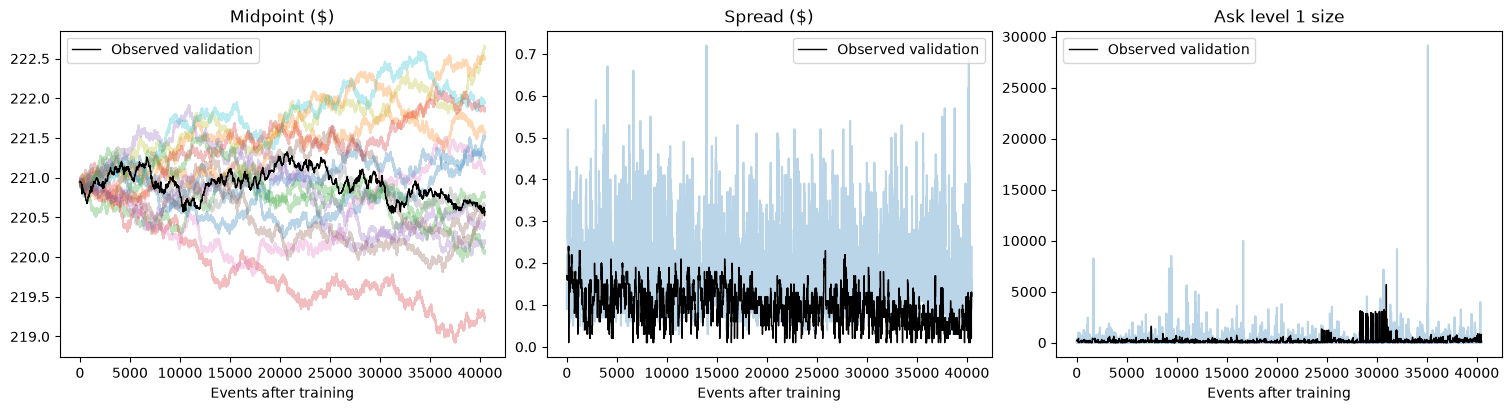

In [3]:
samples = np.array(samples)
generated_features = np.column_stack((midpoint[1:, 0].cpu().numpy(), np.log1p(samples)))
_, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
simulation = (np.exp(midpoint[1:].cpu().numpy()) / 10000, samples[:, 0] / 10000, samples[:, 19])
observed = (np.exp(b["observed"][:, 0]) / 10000, np.expm1(b["observed"][:, 1]) / 10000, np.expm1(b["observed"][:, 20]))
for ax, simulated, actual, title in zip(axes, simulation, observed, ("Midpoint ($)", "Spread ($)", "Ask level 1 size")):
    ax.plot(simulated, alpha=0.3)
    ax.plot(actual, color="black", linewidth=1, label="Observed validation")
    ax.set(title=title, xlabel="Events after training")
    ax.legend()